# CP · Через які місця на дорогах проходить під'їзд до рубок?

**Тип:** сценарний аналіз. **Навіщо:** Чи можна кількома камерами на дорогах побачити більшість під'їздів до місць, де пізніше зрубали ліс.

Цей ноутбук повторює блок сторінки досліджень `web/science/#cp` і бере ті самі результати.

In [1]:
import sys
sys.path.insert(0, '..')
import pandas as pd
from eaglewings.ds import report
pd.set_option('display.width', 200)
%matplotlib inline

## Постановка, дані, протокол і метрики

Текст узято з модуля задачі, той самий записується в журнал кожного запуску.

In [2]:
print(report.protocol('CP'))

CP · Де в парку ставити камери: які місця на дорогах перехоплять під'їзд до майбутніх рубок.

Задача      обрати 10 місць на дорогах і стежках для наземних камер і фотопасток. Камера бачить лише свій
            відрізок дороги, тому рельєф тут мало що дає, важливо, через що проходить під'їзд.
Дані        дороги OSM, гекси H3 res 9, нові втрати лісу Hansen поза згарищами (LG), пожежі FIRMS (TP).
Припущення  до місця їдуть найкоротшим шляхом від в'їзду в парк. Це припущення: реальних проїздів у нас немає.
Протокол    прогресивний, як у TP і LG: для кожного року Y місця ставимо лише за тим, що відомо до Y, і перевіряємо на подіях року Y.
            Валідація 2018–2020, тест 2021–2025 разом і по роках. Вибір лише на валідації, за рубками.
            Різниця з випадковими місцями: парний бутстреп за рубками тесту.
            Перший протокол мав тест 2023–2024: там лише 2 рубки, результат 0 %. Він лишається в звіті як narrow.
Метрики     log: частка рубок, під'їзд до яких проходить через

## Результат

Обраний підхід виділено. Вибір робився лише на валідації, числа тут з тесту.

,label,log,log_lo,log_hi,fire,forest,diff,diff_lo,diff_hi,champion
0,degree · усі,0.261,0.087,0.478,0.000,0.072,0.217,0.046,0.422,False
1,hotspot · усі,0.000,0.000,0.000,0.000,0.071,-0.044,-0.056,-0.033,False
2,greedy_flat · усі,0.783,0.609,0.957,0.083,0.572,0.739,0.569,0.900,True
3,greedy_flat · лісові,0.696,0.478,0.870,0.056,0.527,0.652,0.448,0.823,False
4,greedy_past · усі,0.087,0.000,0.217,0.028,0.363,0.043,-0.048,0.172,False
5,greedy_past · лісові,0.087,0.000,0.217,0.028,0.363,0.043,-0.046,0.172,False
6,greedy_lg · усі,0.609,0.391,0.826,0.083,0.525,0.565,0.354,0.768,False
7,greedy_lg · лісові,0.696,0.478,0.870,0.056,0.527,0.652,0.447,0.822,False
8,random · лісові,0.044,0.033,0.056,0.007,0.045,0.000,0.000,0.000,False


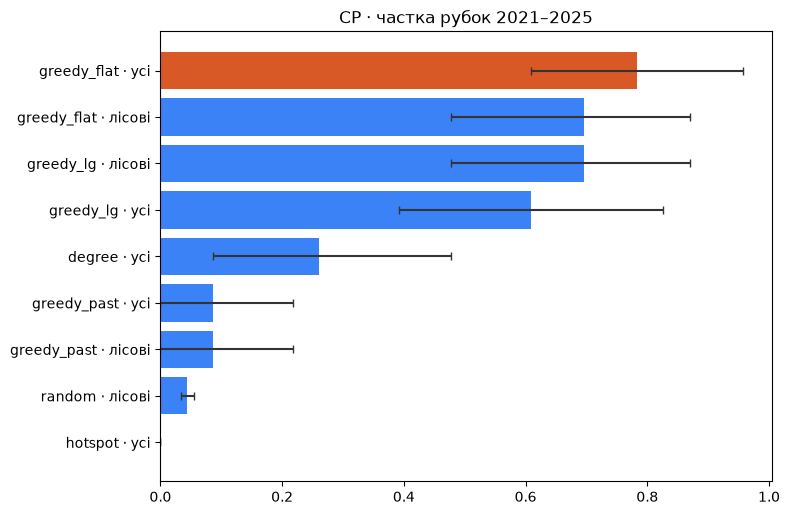

In [3]:
table, fig = report.show('CP')
table

## По роках

Прогресивний протокол: кожен рік бачить лише дані до нього.

In [4]:
report.by_year('CP')

approach,degree,greedy_flat,greedy_lg,greedy_past,hotspot,random
year,,,,,,
2018.0,0.000,0.623,0.574,0.213,0.066,0.034
2019.0,0.000,0.545,0.455,0.545,0.000,0.039
2021.0,0.167,0.833,0.778,0.111,0.000,0.052
2022.0,1.000,1.000,0.000,0.000,0.000,0.017
2023.0,0.000,0.000,0.000,0.000,0.000,0.004
2024.0,0.000,0.000,0.000,0.000,0.000,0.014
